In [1]:
import os, random, subprocess
import numpy as np
import pandas as pd
import nibabel as nb
import scipy.ndimage as ndim
from nilearn import masking, image
from nibabel import processing
from nilearn.plotting import plot_roi, plot_anat
from intensity_normalization.typing import Modality, TissueType
from intensity_normalization.normalize.fcm import FCMNormalize

### 0. Parameters
Please select which dataset to perform the analysis on:

In [2]:
dataset = "bruxelles-bids"
baseline, sd = "ses-b9", "ses-sd9"

Please select the parameters for HTCondor submission scripts:

In [3]:
# Resources
cpus = "4"
ram = "32G"
disk = "90G"

# Directories
root = "/data/project/sleep_ENIGMA_glymphatic/enigma-sd"
symlink = f"{root}/{dataset}/.git/annex/objects"
output = f"{root}/{dataset}/derivatives"
logs = f"{root}/code/logs"
work = "/tmp"

# Executables
conda = "/home/jd.elberse/anaconda3/bin/conda"
singularity = "/usr/bin/singularity"
bash = "/bin/bash"

# Create output and log directory
os.makedirs(output, exist_ok=True)
os.makedirs(logs, exist_ok=True)

Set working directory:

In [4]:
%cd $root

/data/project/sleep_ENIGMA_glymphatic/enigma-sd


Create a function for submitting condor jobs:

In [5]:
def submit(jobname, executable, arguments):
    submission = f"""
        universe        = vanilla
        getenv          = True 
        request_cpus    = {cpus}
        request_memory  = {ram}
        request_disk    = {disk}
        executable      = {executable}
        arguments       = {arguments}
        log             = {logs}/{dataset}_{jobname}_$(Cluster)_$(Process)_log.txt
        output          = {logs}/{dataset}_{jobname}_$(Cluster)_$(Process)_out.txt
        error           = {logs}/{dataset}_{jobname}_$(Cluster)_$(Process)_err.txt
        Queue
    """

    try:
        # Use subprocess to send the content directly to condor_submit
        result = subprocess.run(
            ["condor_submit"],
            input=submission,
            text=True,
            capture_output=True,
            check=True
        )
        print("Job submitted successfully!")
        print(result.stdout)  # Output from condor_submit
    except subprocess.CalledProcessError as e:
        print("Failed to submit job.")
        print(e.stderr)  # Error message from condor_submit

Finally, set up a pandas dataframe for collecting the output.

In [6]:
participants = pd.read_csv(dataset+"/participants.tsv", sep="\t") # Open the participant demographic dataset
subs = participants["participant_id"]
output_data = participants[["participant_id","age","sex","kss_score_baseline","kss_score_sd","chronotype"]] # Select columns for statistical analysis

### 1. Preprocessing
Anatomical preprocessing is run done with fmriprep. Diffusion preprocessing is done with qsiprep. Make sure the correct versions are present:

In [10]:
fmriprep = "code/containers/images/bids/bids-fmriprep--24.1.1.sing"
qsiprep = "code/containers/images/bids/bids-qsiprep--0.24.0.sing"
!datalad get $fmriprep $qsiprep

action summary:
  get (notneeded: 3)


To keep anatomical sessions separate, we need to create two bids filter files:

In [7]:
%%bash -s "$baseline" "$sd"
for ses in $1 $2;
do
    jq -n \
        --arg datatype 'anat' \
        --arg session $ses \
        --arg suffix 'T1w' \
        '{T1w: $ARGS.named}' > code/preproc/filter_${ses}.json
done

Then we can run fmriprep:

In [17]:
for ses in baseline, sd:
    fmriprep_run = (
        "run " # Singularity command
        "--cleanenv "
        f"-B {symlink},{work},{dataset},{output},/opt/freesurfer/7.4/license.txt:/opt/freesurfer/license.txt "
        f"{fmriprep} " # Singularity container
        f"{dataset} " # BIDS data directory
        f"{output} " # Output directory
        "participant "
        "--anat-only "
        "--skull-strip-fixed-seed "
        "--output-spaces MNI152NLin2009cAsym "
        f"--work-dir {work} "
        f"--bids-filter-file preproc/filter_{ses}.json "
    )

    submit(singularity, fmriprep_run)

Failed to submit job.

ERROR: on Line 9 of submit file: 

ERROR: Failed to parse command file (line 9).

Failed to submit job.

ERROR: on Line 9 of submit file: 

ERROR: Failed to parse command file (line 9).



Let fmriprep run for a few hours. If the dataset has diffusion-weighted data, run qsiprep afterwards:

In [80]:
qsiprep_run = (
    "run " # Singularity command
    "--cleanenv "
    f"-B {symlink},{work},{dataset},{output},/opt/freesurfer/7.4/license.txt:/opt/freesurfer/license.txt "
    f"{qsiprep} " # Singularity container
    f"{dataset} " # BIDS data directory
    f"{output} " # Output directory
    "participant "
    "--dwi-only"
    f"--session-id {baseline} {sd} "
    "--output-resolution 1"
)

submit(singularity, qsiprep_run)

Job submitted successfully! Cluster ID: 4562963


/home/jd.elberse/anaconda3/envs/dcm2bids/lib/python3.11/site-packages/htcondor/_deprecation.py:41: FutureWarning: Schedd.transaction() was deprecated in version 10.7.0 and will be removed in a future release.  Use Schedd.submit() instead.
  warnings.warn(message, FutureWarning)
/home/jd.elberse/anaconda3/envs/dcm2bids/lib/python3.11/site-packages/htcondor/_deprecation.py:41: FutureWarning: Submit.queue() was deprecated in version 10.7.0 and will be removed in a future release.  Use Schedd.submit() instead.
  warnings.warn(message, FutureWarning)
/home/jd.elberse/anaconda3/envs/dcm2bids/lib/python3.11/site-packages/htcondor/_lock.py:70: UserWarning: the line 'Queue = 1' was unused by Submit object. Is it a typo?
  rv = func(*args, **kwargs)


We use the FMRIPrep transformation matrix to take the Freesurfer derivative aparc+aseg.mgz and warp it from the Freesurfer Native to FMRIPrep T1 space.

In [31]:
for sub in subs:
    for ses in baseline, sd:
        print(f"{sub} : {ses}")
        freesurfer_path = f"{root}/{dataset}/derivatives/fmriprep/{sub}/{ses}/sourcedata/freesurfer/{sub}/mri"
        fmriprep_path = f"{root}/{dataset}/derivatives/fmriprep/{sub}/{ses}/{sub}/{ses}/anat"
                
        fsnative_to_t1 = (
            "antsApplyTransforms "
            "-d 3 "
            f"-i {freesurfer_path}/aparc+aseg.mgz "
            f"-r {fmriprep_path}/{sub}_{ses}_desc-preproc_T1w.nii.gz "
            f"-t {fmriprep_path}/{sub}_{ses}_from-fsnative_to-T1w_mode-image_xfm.txt "
            "-n NearestNeighbor "
            f"-o {fmriprep_path}/{sub}_{ses}_aparc+aseg.nii.gz "
            "--verbose"
        )

        fmriprep_run = (
            "exec " # Singularity command
            f"-B {symlink},{work},{root}/{dataset},/opt/freesurfer/7.4/license.txt:/opt/freesurfer/license.txt "
            f"{fmriprep} " # We use the fmriprep container because it contains both Freesurfer and ANTS
            f"{fsnative_to_t1} "
        )
        submit("fsnative_to_t1", singularity, fmriprep_run)

sub-001 : ses-b9
Job submitted successfully!
Submitting job(s).
1 job(s) submitted to cluster 4693215.

sub-001 : ses-sd9
Job submitted successfully!
Submitting job(s).
1 job(s) submitted to cluster 4693216.



Then we can warp the resulting derivative from T1 to MNI space.

In [32]:
for sub in subs:
    for ses in baseline, sd:
        print(f"{sub} : {ses}")
        fmriprep_path = f"{root}/{dataset}/derivatives/fmriprep/{sub}/{ses}/{sub}/{ses}/anat"
                
        t1_to_mni = (
            "antsApplyTransforms "
            "-d 3 "
            f"-i {fmriprep_path}/{sub}_{ses}_aparc+aseg.nii.gz "
            f"-r {fmriprep_path}/{sub}_{ses}_space-MNI152NLin2009cAsym_desc-preproc_T1w.nii.gz "
            f"-t {fmriprep_path}/{sub}_{ses}_from-T1w_to-MNI152NLin2009cAsym_mode-image_xfm.h5 "
            "-n NearestNeighbor "
            f"-o {fmriprep_path}/{sub}_{ses}_space-MNI152NLin2009cAsym_aparc+aseg.nii.gz "
            "--verbose"
        )

        fmriprep_run = (
            "exec " # Singularity command
            f"-B {symlink},{work},{root}/{dataset},/opt/freesurfer/7.4/license.txt:/opt/freesurfer/license.txt "
            f"{fmriprep} " # We use the fmriprep container because it contains both Freesurfer and ANTS
            f"{t1_to_mni} "
        )
        submit("t1_to_mni", singularity, fmriprep_run)

sub-001 : ses-b9
Job submitted successfully!
Submitting job(s).
1 job(s) submitted to cluster 4693231.

sub-001 : ses-sd9
Job submitted successfully!
Submitting job(s).
1 job(s) submitted to cluster 4693232.



Double check if all subjects were preprocessed successfully, and if all required files are present.

### 2. Perivascular Space Segmentation
To segment the perivascular spaces (PVS) from anatomical scans, we will use the SHIVA U-Net. First, we have to perform additional preprocessing to make the images readable by the model.

The following block performs the following steps:
* Conform the T1 and mask to 1mm isotropic and RAS orientation
* Normalize the intensities of the T1 scan using Fuzzy C-Means (FCM)
* Create a BG (basal ganglia) mask
* Crop the image and WM/BG masks to (160,214,176)
* Save the output image with the "SHIVA" suffix

In [56]:
for sub in subs:
    for ses in baseline, sd:
        print(f"{sub} : {ses}")
        # Parameters
        fmriprep_path = f"{root}/{dataset}/derivatives/fmriprep/{sub}/{ses}/{sub}/{ses}/anat"
        t1_path = f"{fmriprep_path}/{sub}_{ses}_space-MNI152NLin2009cAsym_desc-preproc_T1w.nii.gz"
        mask_path = f"{fmriprep_path}/{sub}_{ses}_space-MNI152NLin2009cAsym_desc-brain_mask.nii.gz"
        wm_path = f"{fmriprep_path}/{sub}_{ses}_space-MNI152NLin2009cAsym_label-WM_probseg.nii.gz"
        aseg_path = f"{fmriprep_path}/{sub}_{ses}_space-MNI152NLin2009cAsym_aparc+aseg.nii.gz"

        if os.path.exists(fmriprep_path) == False:
            continue

        t1 = nb.load(t1_path)
        mask = nb.load(mask_path)
        aseg = nb.load(aseg_path)
        wm = nb.load(wm_path)

        #plot_anat(t1, title=f"{sub}: {ses} T1")

        #Creating BG mask
        print("[1/5] BG Mask Creation")
        bg_labels = [11, 50, 12, 51, 13, 52, 26, 58]
        bg_mask = np.isin(aseg.get_fdata(), bg_labels).astype(np.uint8)
        bg = nb.Nifti1Image(bg_mask, aseg.affine, aseg.header)

        #plot_roi(bg, title=f"{sub}: {ses} Basal Ganglia Mask")

        # Conformation
        print("[2/5] Conformation")
        t1_conf = nb.processing.conform( # Conform the image
            from_img = t1,
            voxel_size=(1.0,1.0,1.0), # With the desired voxel size
            orientation="RAS")
    
        mask_conf = nb.processing.conform( # Conform the image
            from_img = mask,
            voxel_size=(1.0,1.0,1.0), # With the desired voxel size
            orientation="RAS")
        
        wm_conf = nb.processing.conform( # Conform the image
            from_img = wm,
            voxel_size=(1.0,1.0,1.0), # With the desired voxel size
            orientation="RAS")
        
        bg_conf = nb.processing.conform( # Conform the image
            from_img = bg,
            voxel_size=(1.0,1.0,1.0), # With the desired voxel size
            orientation="RAS")
        
        #plot_anat(t1_conf, title=f"{sub}: {ses} T1 Conformed") # Plotting function
    
        #Normalization
        print("[3/5] Normalization")
        fcm_norm = FCMNormalize(tissue_type=TissueType.WM)
        t1_norm_data = fcm_norm(t1_conf.get_fdata(), mask_conf.get_fdata())
        t1_norm = nb.Nifti1Image(t1_norm_data, t1_conf.affine)

        #plot_anat(t1_norm, title=f"{sub}: {ses} T1 Normalized") # Plotting function

        #Cropping
        print("[4/5] Cropping")
        size = (160,214,176) # Desired output size of the crop
    
        mask_array = np.array(mask_conf.dataobj) # Set mask object to ndarray
        cm = ndim.center_of_mass(mask_array) # Find the center of mass
        cm = [round(val) for val in cm] # Round the values

        dim = np.zeros([3,2], dtype = 'int') # Obtain dimensions of the desired image
        for i in [0,1,2]:
            dim[i,0] = int(cm[i]-size[i]/2)
            dim[i,1] = int(cm[i]+size[i]/2)

            if dim[i,0] < 0:
                dim[i,:] = dim[i,:]-dim[i,0]

            if dim[i,1] > 256:
                dim[i,:] = dim[i,:]-(dim[i,1]-256)
            
        t1_crop = t1_norm.slicer[dim[0,0]:dim[0,1],dim[1,0]:dim[1,1],dim[2,0]:dim[2,1]]
        wm_crop = wm_conf.slicer[dim[0,0]:dim[0,1],dim[1,0]:dim[1,1],dim[2,0]:dim[2,1]]
        bg_crop = bg_conf.slicer[dim[0,0]:dim[0,1],dim[1,0]:dim[1,1],dim[2,0]:dim[2,1]]

        #plot_anat(t1_crop, title=f"{sub}: {ses} T1 Cropped") # Plotting function

        print("[5/5] Saving derivatives")
        nb.save(t1_crop, t1_path.replace("space-MNI152NLin2009cAsym","space-SHIVA"))
        nb.save(wm_crop, wm_path.replace("space-MNI152NLin2009cAsym","space-SHIVA"))
        nb.save(bg_crop, wm_path.replace("space-MNI152NLin2009cAsym_label-WM","space-SHIVA_label-BG"))

sub-001 : ses-b9
[1/5] BG Mask Creation
[2/5] Conformation
[3/5] Normalization
[4/5] Cropping
[5/5] Saving derivatives
sub-001 : ses-sd9
[1/5] BG Mask Creation
[2/5] Conformation
[3/5] Normalization
[4/5] Cropping
[5/5] Saving derivatives
sub-002 : ses-b9


FileNotFoundError: No such file or no access: '/data/project/sleep_ENIGMA_glymphatic/enigma-sd/bruxelles-bids/derivatives/fmriprep/sub-002/ses-b9/sub-002/ses-b9/anat/sub-002_ses-b9_space-MNI152NLin2009cAsym_aparc+aseg.nii.gz'

Select a random subject and inspect the computed derivatives.

FileNotFoundError: No such file or no access: '/data/project/sleep_ENIGMA_glymphatic/enigma-sd/bruxelles-bids/derivatives/fmriprep/sub-014/ses-b9/sub-014/ses-b9/anat/sub-014_ses-b9_space-SHIVA_desc-preproc_T1w.nii.gz'

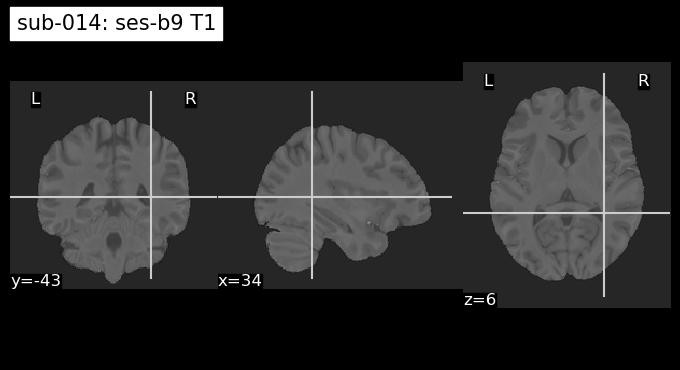

In [47]:
sub = random.choice(subs)
ses = "ses-b9"

fmriprep_path = f"{root}/{dataset}/derivatives/fmriprep/{sub}/{ses}/{sub}/{ses}/anat"
t1_path = f"{fmriprep_path}/{sub}_{ses}_space-MNI152NLin2009cAsym_desc-preproc_T1w.nii.gz"
t1_shiva_path = f"{fmriprep_path}/{sub}_{ses}_space-SHIVA_desc-preproc_T1w.nii.gz"
bg_path = f"{fmriprep_path}/{sub}_{ses}_space-SHIVA_label-BG_probseg.nii.gz"
wm_path = f"{fmriprep_path}/{sub}_{ses}_space-SHIVA_label-WM_probseg.nii.gz"

plot_anat(nb.load(t1_path), title=f"{sub}: {ses} T1")
plot_anat(nb.load(t1_shiva_path), title=f"{sub}: {ses} T1 SHIVA Preprocessed")
plot_roi(nb.load(bg_path), title=f"{sub}: {ses} SHIVA BG Mask")
plot_roi(nb.load(wm_path), title=f"{sub}: {ses} SHIVA WM Mask")

Obtain SHIVA scripts from GitHub. Due to filesize, the pre-trained weights need to be downloaded manually from https://cloud.efixia.com/sharing/wknXOu07H and stored in code/shiva/models.

In [40]:
%%bash
datalad clone -d . https://github.com/pboutinaud/SHIVA_PVS code/shiva # Clone from GitHub
mkdir -p code/shiva/models

subdataset(ok): code/shiva (dataset)
action summary:
  install (notneeded: 1)
  save (notneeded: 1)


SHIVA inference needs to be run on a CUDA-capable GPU. This means we have to edit our submit parameters a bit.

In [41]:
def shiva_submit(jobname, executable, arguments):
    submission = f"""
        universe        = vanilla
        getenv          = False
        request_GPUs    = 1
        require_gpus = Capability >= 6.1
        request_memory  = {ram}
        request_disk    = {disk}
        executable      = {executable}
        arguments       = {arguments}
        log             = {logs}/{dataset}_{jobname}_$(Cluster)_$(Process)_log.txt
        output          = {logs}/{dataset}_{jobname}_$(Cluster)_$(Process)_out.txt
        error           = {logs}/{dataset}_{jobname}_$(Cluster)_$(Process)_err.txt
        Queue
    """

    try:
        # Use subprocess to send the content directly to condor_submit
        result = subprocess.run(
            ["condor_submit"],
            input=submission,
            text=True,
            capture_output=True,
            check=True
        )
        print("Job submitted successfully!")
        print(result.stdout)  # Output from condor_submit
    except subprocess.CalledProcessError as e:
        print("Failed to submit job.")
        print(e.stderr)  # Error message from condor_submit

Then we can run the inference:

In [ ]:
for sub in subs[0:1]:
    for ses in baseline, sd:
        # Parameters
        fmriprep_path = f"{root}/{dataset}/derivatives/fmriprep/{sub}/{ses}/{sub}/{ses}/anat"
        t1_path = f"{fmriprep_path}/{sub}_{ses}_space-SHIVA_desc-preproc_T1w.nii.gz"
        out_path = t1_path.replace('desc-preproc_T1w','label-PVS_probseg')
        models = " ".join(f"-m code/shiva/models/{model}" for model in os.listdir("code/shiva/models"))

        # SHIVA arguments
        shiva_infer = (
            "run -n SHIVA_PVS "
            "python code/shiva/predict_one_file.py " # Shiva inference script
            "--verbose "
            "--gpu 0 "
            f"{models} "
            f"-i {t1_path} "
            f"-o {out_path}"
        )

        shiva_submit(jobname=f"{sub}_{ses}_SHIVA", executable=conda, arguments=shiva_infer)

Job submitted successfully!
Submitting job(s).
1 job(s) submitted to cluster 4693797.

Job submitted successfully!
Submitting job(s).
1 job(s) submitted to cluster 4693798.



Finally, we open the PVS segmentations and perform a few final adjustments:
* Thresholding at 0.5 intensity
* Masking with WM and BG segmentations

sub-001 : ses-sd9
[1/3] Thresholding at 0.5


/tmp/ipykernel_510174/3997010718.py:16: FutureWarning: From release 0.13.0 onwards, this function will, by default, copy the header of the input image to the output. Currently, the header is reset to the default Nifti1Header. To suppress this warning and use the new behavior, set `copy_header=True`.
  pvs_thresh = image.threshold_img(pvs_path, threshold = float(0.5), copy="True")


[2/3] Creating PVS mask
[3/3] Masking


TypeError: numpy boolean subtract, the `-` operator, is not supported, use the bitwise_xor, the `^` operator, or the logical_xor function instead.

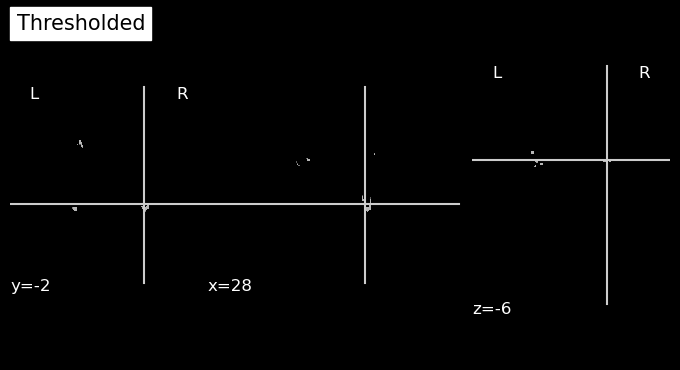

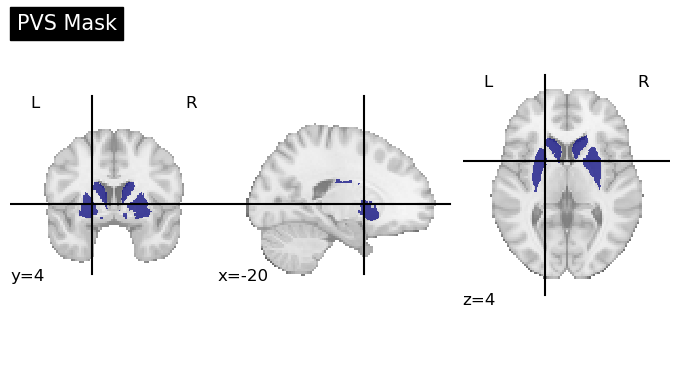

In [55]:
for sub in subs[0:1]:
    for ses in baseline, sd:

        if ses == baseline:
            continue
        # Parameters
        print(f"{sub} : {ses}")
        fmriprep_path = f"{root}/{dataset}/derivatives/fmriprep/{sub}/{ses}/{sub}/{ses}/anat"
        pvs_path = f"{fmriprep_path}/{sub}_{ses}_space-SHIVA_label-PVS_probseg.nii.gz"
        bg_path = f"{fmriprep_path}/{sub}_{ses}_space-SHIVA_label-BG_probseg.nii.gz"
        wm_path = f"{fmriprep_path}/{sub}_{ses}_space-SHIVA_label-WM_probseg.nii.gz"

        # Threshold
        print("[1/3] Thresholding at 0.5")
        pvs = nb.load(pvs_path)
        pvs_thresh = image.threshold_img(pvs_path, threshold = float(0.5), copy="True")

        plot_anat(pvs_thresh, title="Thresholded")

        # Create combined mask
        print("[2/3] Creating PVS mask")
        bg = nb.load(bg_path)
        wm = nb.load(wm_path)
        pvs_mask_data = np.logical_and(bg.get_fdata(), wm.get_fdata())
        pvs_mask = nb.Nifti1Image(pvs_mask_data, bg.affine, bg.header)

        plot_roi(pvs_mask, title="PVS Mask")

        # Mask
        print("[3/3] Masking")
        pvs_seg_data = masking.apply_mask(pvs_thresh, pvs_mask)
        pvs_seg = nb.Nifti1Image(pvs_mask_data, pvs.affine, pvs.header)
        plot_anat(pvs_seg, title="Final")


### 3. Relative Free Water Index
To obtain the relative free water index (RFWI), we use the Dipy free water elimination model. 